# 🏭 DL & GenAI Project (T3-2026) — Milestone 4 notebook
Roll no. `23f3001567` · W&B project `23f3001567-t32026`

**How to use:** Kaggle → add the competition data → GPU T4 + Internet ON + secret `WANDB_API_KEY` → *Run All* (≈ 15–20 min).
The last cell prints an **ANSWER SHEET**: one line per question, already in the exact "Answer format" of the Google Form. Copy each line into its box (the toy/arithmetic questions Q4–Q7 are computed by code too, so you can see the working).

| Question | Topic | How it is answered |
|---|---|---|
| Q1 | image / class imbalance on the 1,200-image subset | data |
| Q2 | pixel imbalance, `pos_weight` for `defect_b` | data |
| Q3 | bounded square-root sampler | data |
| Q4 | warm-up + cosine schedule, stepping-cadence bug | formula |
| Q5 | early-stopping trace | simulation of the rule |
| Q6 | AMP memory + gradient accumulation | arithmetic |
| Q7 | Naive-Dice trap + official metric | data + toy |
| Q8 | training dynamics (6 epochs, warm-up + cosine) | **training run R1** |
| Q9 | defect-size bins | data |
| Q10 | OFAT experiments R0, R0b, R1, R2 | **4 training runs, all logged to W&B** |

**Assumptions (change in the settings cell if your Milestone 2/3 baseline differs):**
* Baseline model = the **from-scratch U-Net** (`BASELINE_MODEL = "scratch"`; use `"resnet34"` for the pretrained one). Loss = BCE + soft Dice, light flips as augmentation, AdamW (lr 3e-4), batch 16, AMP, seed 42, threshold 0.5, no minimum area — exactly the fixed settings of the Common Setup.
* The Q8 run is **the same run as R1** of Q10 (constant-LR baseline + warm-up/cosine, natural sampling), because Q8 specifies "warm-up + cosine" and nothing else. It is logged once in W&B as `m4_R1_warmup_cosine`.
* Warm-up = 60 optimizer steps (1 epoch); cosine decays over the remaining steps of the 6-epoch run (360 steps in total).

In [27]:
# ===================== SETTINGS =====================
ROLL_NO       = "23f3001567"
WANDB_PROJECT = f"{ROLL_NO}-t32026"
INPUT_ROOT, OUT_DIR = "/kaggle/input", "/kaggle/working"
QUICK_TEST    = False            # True = 1 epoch per run, only to check that the code runs (answers are then meaningless)
BASELINE_MODEL = "scratch"       # "scratch" (Milestone 2 baseline U-Net) or "resnet34"
SEED, N_IMAGES = 42, 1200
EPOCHS, BATCH, LR, THR = (1 if QUICK_TEST else 6), 16, 3e-4, 0.5

import os, json, math, random, copy, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")
H, W    = 128, 800
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
os.makedirs(OUT_DIR, exist_ok=True)
ANS = {}          # formatted answers for the Google Form are collected here
print("settings ok | epochs per run:", EPOCHS)

settings ok | epochs per run: 6


## 0. Common setup — working subset and split
Unique `image_id`s sorted in ASCII order → first 1,200 → all 4 rows each (4,800 pairs). Masks decoded on the native 128×800 canvas (column-major / Fortran order, 1-based), runs that exceed 102,400 pixels are clipped.

In [28]:
def find_file(root, names):
    for dirpath, _, files in os.walk(root):
        for n in names:
            if n in files: return os.path.join(dirpath, n)
TRAIN_CSV = find_file(INPUT_ROOT, ["train.csv", "train_1.csv"])
assert TRAIN_CSV, "train.csv not found - did you add the competition as Input?"
train_df = pd.read_csv(TRAIN_CSV)

def rle_to_mask(rle, shape=(H, W)):
    # 'start length start length ...' (1-based, column-major) -> 0/1 array; runs beyond the canvas are clipped
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        nums = np.array(rle.split(), dtype=np.int64)
        for s, l in zip(nums[0::2] - 1, nums[1::2]):
            a, b = max(int(s), 0), min(int(s + l), H * W)
            if b > a: flat[a:b] = 1
    return flat.reshape(shape, order="F")

IDS = sorted(train_df.image_id.astype(str).unique())[:N_IMAGES]           # ASCII order, first 1,200
train_df["image_id"] = train_df.image_id.astype(str)
sub_df = train_df[train_df.image_id.isin(IDS)]
assert len(sub_df) == 4 * N_IMAGES, f"expected {4 * N_IMAGES} rows, got {len(sub_df)}"
pivot = sub_df.pivot(index="image_id", columns="defect_type", values="mask_rle")[CLASSES].fillna("").loc[IDS]
N = len(IDS)
MASKS = np.zeros((N, 4, H, W), dtype=np.uint8)
for i, row in enumerate(pivot.values):
    for c in range(4): MASKS[i, c] = rle_to_mask(row[c])
AREA = MASKS.sum((2, 3)).astype(np.int64)          # (N, 4) pixels per image-class pair
HAS  = AREA > 0                                    # (N, 4) positive pairs
COMBO = np.array(["+".join(c for c, h in zip(CLASSES, r) if h) or "clean" for r in HAS])

# ---- 80/20 split stratified on the combination string; combinations with < 2 images -> rare_other ----
cnt = pd.Series(COMBO).value_counts()
strat = np.array([c if cnt[c] >= 2 else "rare_other" for c in COMBO])
if (strat == "rare_other").sum() == 1:             # a stratified split cannot handle a group of one -> join the smallest real group
    smallest = pd.Series(strat[strat != "rare_other"]).value_counts().idxmin(); strat[strat == "rare_other"] = smallest
    print("note: rare_other had a single image, merged into", smallest)
train_idx, val_idx = train_test_split(np.arange(N), test_size=0.2, stratify=strat, random_state=SEED)
print(f"{N} images, {len(sub_df)} pairs | train {len(train_idx)} | validation {len(val_idx)}   (expected 960 / 240)")

note: rare_other had a single image, merged into defect_a+defect_b
1200 images, 4800 pairs | train 960 | validation 240   (expected 960 / 240)


## Question 1 — image-level and class-level imbalance

In [29]:
q1_a = int((COMBO == "clean").sum())
q1_b = [int(HAS[:, c].sum()) for c in range(4)]
q1_c = int(cnt.shape[0])
q1_d = (int(cnt.max()), int(cnt.min()))
print("combination groups:\n", cnt.to_string())
print(f"\n(a) clean images: {q1_a}\n(b) positives per class: {dict(zip(CLASSES, q1_b))}\n(c) unique combination strings: {q1_c}\n(d) largest / smallest group: {q1_d}")
ANS["Q1"] = f"{q1_a}; {q1_b[0]}, {q1_b[1]}, {q1_b[2]}, {q1_b[3]}; {q1_c}; {q1_d[0]}, {q1_d[1]}"

combination groups:
 clean                         578
defect_c                      334
defect_d                       81
defect_c+defect_d              71
defect_a                       59
defect_b                       22
defect_a+defect_c              21
defect_a+defect_d              14
defect_a+defect_c+defect_d      7
defect_b+defect_d               3
defect_a+defect_b+defect_d      3
defect_a+defect_b               2
defect_b+defect_c+defect_d      2
defect_b+defect_c               2
defect_a+defect_b+defect_c      1

(a) clean images: 578
(b) positives per class: {'defect_a': 107, 'defect_b': 35, 'defect_c': 438, 'defect_d': 181}
(c) unique combination strings: 15
(d) largest / smallest group: (578, 1)


## Question 2 — pixel-level imbalance and `pos_weight` (defect_b)

In [30]:
pos_px = int(AREA[:, 1].sum()); all_px = N * H * W
q2_a = 100 * pos_px / all_px
q2_b = float(AREA[AREA[:, 1] > 0, 1].mean())
q2_c = (all_px - pos_px) / pos_px
print(f"positive pixels {pos_px} of {all_px} | positive defect_b images {(AREA[:, 1] > 0).sum()}")
print(f"(a) positive share: {q2_a:.4f} %\n(b) mean area among defect_b-positive images: {q2_b:.1f} px\n(c) negative/positive ratio: {q2_c:.2f} -> {round(q2_c)}")
ANS["Q2"] = f"{q2_a:.4f}, {q2_b:.1f}, {round(q2_c)}"

positive pixels 19654 of 122880000 | positive defect_b images 35
(a) positive share: 0.0160 %
(b) mean area among defect_b-positive images: 561.5 px
(c) negative/positive ratio: 6251.16 -> 6251


## Question 3 — bounded square-root sampler  `w_g = min(sqrt(n_clean / n_g), 5)`

In [31]:
n_clean = int(cnt["clean"])
ratio  = {g: math.sqrt(n_clean / n) for g, n in cnt.items()}
w_g    = {g: min(r, 5.0) for g, r in ratio.items()}
w_img  = np.array([w_g[c] for c in COMBO]); p_img = w_img / w_img.sum()
is_clean, is_b = COMBO == "clean", HAS[:, 1]
q3_a_s, q3_a_n = 100 * p_img[is_clean].sum(), 100 * n_clean / N
q3_b_s, q3_b_n = N * p_img[is_b].sum(), N * is_b.mean()
q3_c = q3_b_s / q3_b_n
q3_d = int(sum(r >= 5.0 - 1e-12 for r in ratio.values()))
print(pd.DataFrame({"n_g": cnt, "sqrt(nclean/n_g)": pd.Series(ratio).round(3), "weight": pd.Series(w_g).round(3)}).to_string())
print(f"\n(a) clean draws: sampler {q3_a_s:.2f} % | natural {q3_a_n:.2f} %\n(b) defect_b draws per epoch: sampler {q3_b_s:.2f} | natural {q3_b_n:.2f}\n(c) enrichment: {q3_c:.2f}x\n(d) groups at the cap of 5: {q3_d}")
ANS["Q3"] = f"{q3_a_s:.2f}, {q3_a_n:.2f}; {q3_b_s:.2f}, {q3_b_n:.2f}; {q3_c:.2f}; {q3_d}"

                            n_g  sqrt(nclean/n_g)  weight
clean                       578             1.000   1.000
defect_c                    334             1.315   1.315
defect_d                     81             2.671   2.671
defect_c+defect_d            71             2.853   2.853
defect_a                     59             3.130   3.130
defect_b                     22             5.126   5.000
defect_a+defect_c            21             5.246   5.000
defect_a+defect_d            14             6.425   5.000
defect_a+defect_c+defect_d    7             9.087   5.000
defect_b+defect_d             3            13.880   5.000
defect_a+defect_b+defect_d    3            13.880   5.000
defect_a+defect_b             2            17.000   5.000
defect_b+defect_c+defect_d    2            17.000   5.000
defect_b+defect_c             2            17.000   5.000
defect_a+defect_b+defect_c    1            24.042   5.000

(a) clean draws: sampler 28.81 % | natural 48.17 %
(b) defect_b draws p

## Question 4 — warm-up + cosine and the stepping-cadence trap

In [32]:
BASE_LR = 3e-4
def mult(t, warm=60, total=480):
    return t / warm if t < warm else 0.5 * (1 + math.cos(math.pi * (t - warm) / (total - warm)))
lr15, lr270, lr400 = (BASE_LR * mult(t) for t in (15, 270, 400))
lr_bug = BASE_LR * mult(8)       # scheduler.step() called once per epoch: after 8 epochs the scheduler counter is only t = 8
print(f"(a) lr(15) = {lr15:.3e} | lr(270) = {lr270:.3e} | lr(400) = {lr400:.3e}\n(b) buggy per-epoch stepping -> t = 8 -> lr = {lr_bug:.3e}")
q4_c = "The learning rate never leaves the warm-up ramp (stays near 4e-5 instead of reaching 3e-4 and decaying), so the loss falls very slowly and the validation curves stay flat/high - the model looks permanently under-trained."
ANS["Q4"] = f"{lr15:.2e}, {lr270:.2e}, {lr400:.2e}; {lr_bug:.2e}; {q4_c}"

(a) lr(15) = 7.500e-05 | lr(270) = 1.500e-04 | lr(400) = 2.606e-05
(b) buggy per-epoch stepping -> t = 8 -> lr = 4.000e-05


## Question 5 — early-stopping trace

In [33]:
scores = [0.512, 0.601, 0.648, 0.661, 0.664, 0.668, 0.671, 0.670, 0.672, 0.669, 0.673, 0.665]
def early_stop(scores, patience, min_delta):
    best, best_ep, bad, stop = -1e9, None, 0, None
    for e, s in enumerate(scores, 1):
        if s > best + min_delta: best, best_ep, bad = s, e, 0
        else:
            bad += 1
            if bad >= patience: stop = e; break
    return stop, best_ep, best
stop_a, best_ep_a, best_a = early_stop(scores, 3, 0.002)
stop_b, best_ep_b, best_b = early_stop(scores, 3, 0.0)
print(f"(a) min_delta 0.002: stops at epoch {stop_a}, restores epoch {best_ep_a} (score {best_a})")
print(f"(b) min_delta 0    : stops within 12 epochs? {'yes' if stop_b else 'no'} | best checkpoint at epoch 12 = epoch {best_ep_b} ({best_b})")
ANS["Q5"] = f"{stop_a}, {best_ep_a}, {best_a:.3f}; {'yes' if stop_b else 'no'}, {best_ep_b}"

(a) min_delta 0.002: stops at epoch 10, restores epoch 7 (score 0.671)
(b) min_delta 0    : stops within 12 epochs? no | best checkpoint at epoch 12 = epoch 11 (0.673)


## Question 6 — mixed precision, GPU memory, gradient accumulation

In [34]:
P = 25_000_000
state_mb = P * 4 * (1 + 1 + 2) / 1e6                     # weights + grads + 2 AdamW moments, all FP32
act32, act16 = 150.0, 75.0                               # MB per sample
b_fp32, b_amp = state_mb + 16 * act32, state_mb + 16 * act16
c_fp32, c_amp = int((3400 - state_mb) // act32), int((3400 - state_mb) // act16)
micro, accum = 8, 4
eff_bs = micro * accum
n_micro = 960 // micro; n_steps = n_micro // accum
assert 960 % micro == 0 and n_micro % accum == 0, "a partial batch would occur"
warm_steps = 2 * n_steps
print(f"(a) weights+grads+AdamW: {state_mb:.0f} MB\n(b) batch 16: FP32 {b_fp32:.0f} MB | AMP {b_amp:.0f} MB\n(c) largest batch in 3400 MB: FP32 {c_fp32} | AMP {c_amp}")
print(f"(d) effective batch {eff_bs}\n(e) {n_micro} micro-batches, {n_steps} optimizer steps per epoch\n(f) divide each micro-batch loss by {accum}\n(g) 2-epoch warm-up = {warm_steps} optimizer steps")
ANS["Q6"] = f"{state_mb:.0f}; {b_fp32:.0f}, {b_amp:.0f}; {c_fp32}, {c_amp}; {eff_bs}; {n_micro}, {n_steps}; {accum}; {warm_steps}"

(a) weights+grads+AdamW: 400 MB
(b) batch 16: FP32 2800 MB | AMP 1600 MB
(c) largest batch in 3400 MB: FP32 20 | AMP 40
(d) effective batch 32
(e) 120 micro-batches, 30 optimizer steps per epoch
(f) divide each micro-batch loss by 4
(g) 2-epoch warm-up = 60 optimizer steps


## Question 7 — the Naive-Dice trap and the official metric

In [35]:
PIX = H * W
def official_score(inter, pa, ga):
    inter, pa, ga = [np.asarray(a, dtype=np.float64) for a in (inter, pa, ga)]
    pos = ga > 0
    dice = 2 * inter / np.maximum(pa + ga, 1)
    fg = dice[pos].mean() if pos.any() else 0.0
    fp_score = 1 - (pa[~pos] / PIX).mean() if (~pos).any() else 1.0
    empty_acc = (pa[~pos] == 0).mean() if (~pos).any() else 1.0
    return 0.7 * fg + 0.2 * fp_score + 0.1 * empty_acc, fg, fp_score, empty_acc
def naive_dice(inter, pa, ga):                                   # Dice(empty, empty) = 1, Dice(empty, non-empty) = 0
    inter, pa, ga = [np.asarray(a, dtype=np.float64) for a in (inter, pa, ga)]
    return np.where(pa + ga == 0, 1.0, 2 * inter / np.maximum(pa + ga, 1)).mean()

# ---- Part A: all-empty baseline on the 4,800 pairs ----
ga_all = AREA.ravel(); zero = np.zeros_like(ga_all)
q7_a = int((ga_all == 0).sum())
q7_b = naive_dice(zero, zero, ga_all)
q7_c = official_score(zero, zero, ga_all)[0]
print(f"(a) empty ground-truth pairs: {q7_a} of {len(ga_all)}\n(b) baseline naive Dice: {q7_b:.4f}\n(c) baseline official score: {q7_c:.4f}")
# ---- Part B: toy validation set (400 pairs: 60 positive with Dice 0.5, 340 empty, 34 false blobs of 1024 px) ----
ga_t    = np.r_[np.full(60, 1000), np.zeros(340)]
pa_t    = np.r_[np.full(60, 1000), np.zeros(306), np.full(34, 1024)]
inter_t = np.r_[np.full(60, 500),  np.zeros(340)]
q7_d_off, q7_d_nv = official_score(inter_t, pa_t, ga_t)[0], naive_dice(inter_t, pa_t, ga_t)
q7_e = naive_dice(np.zeros(400), np.zeros(400), ga_t)
print(f"(d) toy model: official {q7_d_off:.4f} | naive Dice {q7_d_nv:.4f}")
print(f"(e) all-empty baseline on the toy set: naive Dice {q7_e:.4f}, official {official_score(np.zeros(400), np.zeros(400), ga_t)[0]:.4f}  -> naive Dice ranks the model ({q7_d_nv:.4f}) BELOW the baseline ({q7_e:.4f}); the official score does not.")
ANS["Q7"] = f"{q7_a}; {q7_b:.4f}, {q7_c:.4f}; {q7_d_off:.4f}, {q7_d_nv:.4f}; naive Dice, {q7_e:.4f}"

(a) empty ground-truth pairs: 4039 of 4800
(b) baseline naive Dice: 0.8415
(c) baseline official score: 0.3000
(d) toy model: official 0.6398 | naive Dice 0.8400
(e) all-empty baseline on the toy set: naive Dice 0.8500, official 0.3000  -> naive Dice ranks the model (0.8400) BELOW the baseline (0.8500); the official score does not.


## Question 9 — defect-size binning (data only, answered before training)

In [36]:
areas = AREA[AREA > 0]                                           # every positive image-class pair, all 4 classes pooled
bins = {"1-100 px": (areas >= 1) & (areas <= 100), "101-500 px": (areas >= 101) & (areas <= 500), "501+ px": areas >= 501}
n_bin = {k: int(m.sum()) for k, m in bins.items()}
px_bin = {k: int(areas[m].sum()) for k, m in bins.items()}
q9_a = list(n_bin.values()); q9_b = 100 * px_bin["501+ px"] / areas.sum()
recall = {"1-100 px": 0.30, "101-500 px": 0.70, "501+ px": 0.95}
missed_pairs = {k: n_bin[k] * (1 - recall[k]) for k in bins}
q9_c, q9_cbin = sum(missed_pairs.values()), max(missed_pairs, key=missed_pairs.get)
missed_px = {k: px_bin[k] * (1 - recall[k]) for k in bins}
print(pd.DataFrame({"pairs": n_bin, "pixels": px_bin, "expected missed pairs": {k: round(v, 2) for k, v in missed_pairs.items()}, "expected missed pixels": {k: round(v) for k, v in missed_px.items()}}).to_string())
print(f"\n(a) pairs per bin: {q9_a}\n(b) share of positive pixels in 501+: {q9_b:.2f} %\n(c) expected missed pairs: {q9_c:.2f}; largest contribution: {q9_cbin}")
q9_d = "Bins differ in how many pairs they hold but also hugely in pixels per pair, so the bin with the most missed pairs (many small defects) can contribute few missed pixels, while a few missed large defects can carry most of the missed pixel area."
print("most missed pixels come from:", max(missed_px, key=missed_px.get))
ANS["Q9"] = f"{q9_a[0]}, {q9_a[1]}, {q9_a[2]}; {q9_b:.2f}; {q9_c:.2f}, {q9_cbin}; {q9_d}"

            pairs   pixels  expected missed pairs  expected missed pixels
1-100 px        5      298                   3.50                     209
101-500 px     99    29996                  29.70                    8999
501+ px       657  3953580                  32.85                  197679

(a) pairs per bin: [5, 99, 657]
(b) share of positive pixels in 501+: 99.24 %
(c) expected missed pairs: 66.05; largest contribution: 501+ px
most missed pixels come from: 501+ px


## Training section (Q8 and Q10)
The next cell builds the dataset, loss, metric and the training function. Everything is identical between the four runs except the one factor each run changes (**OFAT**): R0 constant LR + natural sampling · R0b = R0 with seed 7 (noise) · R1 = R0 + warm-up/cosine · R2 = R0 + bounded square-root sampler.

In [37]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, cv2
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from tqdm.auto import tqdm
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); USE_AMP = device.type == "cuda"
NC = 4
print("device:", device, "|", torch.cuda.get_device_name(0) if USE_AMP else "NO GPU -> switch on the T4 accelerator!")

try:                                                           # Weights & Biases (key from the Kaggle secret WANDB_API_KEY)
    from kaggle_secrets import UserSecretsClient
    import wandb
    wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY")); print("✅ W&B login OK, project:", WANDB_PROJECT)
except Exception as e:
    os.environ["WANDB_MODE"] = "disabled"; import wandb
    print("⚠️ W&B DISABLED (", repr(e)[:80], ") -> add the secret WANDB_API_KEY, otherwise the runs are NOT logged")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True

class ConvBlock(nn.Sequential):                                          # (3x3 conv -> BatchNorm -> ReLU) twice
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class SimpleUNet(nn.Module):                                             # MODEL 1: U-Net from scratch
    def __init__(self, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]              # 32, 64, 128, 256, 512 channels
        self.enc = nn.ModuleList([ConvBlock(1, c[0]), ConvBlock(c[0], c[1]), ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])])
        self.bottom = ConvBlock(c[3], c[4])
        self.pool = nn.MaxPool2d(2)                                      # halves height and width
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])   # learnable up-sampling x2
        self.dec = nn.ModuleList([ConvBlock(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], NC, 1)
        nn.init.constant_(self.head.bias, -4.0)                          # start at "~2 % probability" (defects are rare) -> stable start
    def forward(self, x):
        skips = []
        for enc in self.enc:                                             # ENCODER: go down, remember every level
            x = enc(x); skips.append(x); x = self.pool(x)
        x = self.bottom(x)
        for i in (3, 2, 1, 0):                                           # DECODER: go up, add the remembered level (skip connection)
            x = self.dec[i](torch.cat([self.up[i](x), skips[i]], 1))
        return self.head(x)                                              # raw scores (logits) (B, 4, H, W)

class DecoderBlock(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__(); self.conv = ConvBlock(cin + cskip, cout)
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)   # up-sample to the skip's size
        return self.conv(torch.cat([x, skip], 1))

class PretrainedUNet(nn.Module):                                         # pretrained encoder + U-Net decoder
    def __init__(self, arch, enc_ch=None, pretrained=True):
        super().__init__()
        w = "IMAGENET1K_V1" if pretrained else None
        try:
            if arch == "resnet34":
                m = torchvision.models.resnet34(weights=w)
                m.conv1 = self._to_gray(m.conv1)
                self.stages = nn.ModuleList([nn.Sequential(m.conv1, m.bn1, m.relu), nn.Sequential(m.maxpool, m.layer1), m.layer2, m.layer3, m.layer4])
                enc_ch = [64, 64, 128, 256, 512]
            else:                                                        # efficientnet_b0 / b2 / b3 (same stage layout, different widths)
                m = getattr(torchvision.models, arch)(weights=w)
                m.features[0][0] = self._to_gray(m.features[0][0]); f = m.features
                self.stages = nn.ModuleList([f[0:2], f[2], f[3], f[4:6], f[6:8]])
        except Exception as e:
            raise RuntimeError("Could not get the pretrained weights - turn Internet ON in the notebook settings.") from e
        dec_ch, prev, self.decoder = [256, 128, 64, 32], enc_ch[-1], nn.ModuleList()
        for cskip, cout in zip(enc_ch[-2::-1], dec_ch):
            self.decoder.append(DecoderBlock(prev, cskip, cout)); prev = cout
        self.final, self.head = ConvBlock(prev, 16), nn.Conv2d(16, NC, 1)
        nn.init.constant_(self.head.bias, -4.0)
    @staticmethod
    def _to_gray(conv):                                                  # 3-channel conv -> 1-channel conv (weights summed)
        new = nn.Conv2d(1, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=False)
        new.weight.data = conv.weight.data.sum(1, keepdim=True); return new
    def forward(self, x):
        feats = []
        for stage in self.stages:
            x = stage(x); feats.append(x)
        d = feats[-1]
        for block, skip in zip(self.decoder, reversed(feats[:-1])):
            d = block(d, skip)
        d = F.interpolate(d, scale_factor=2, mode="bilinear", align_corners=False)
        return self.head(self.final(d))

def build_model(name):
    return SimpleUNet() if name == "scratch" else PretrainedUNet("resnet34", None, True)


# ---- images of the 1,200-image subset (read once into RAM) ----
def load_gray(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return img if img.shape == (H, W) else cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA)
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
train_dir = max(((d, sum(f.lower().endswith(IMG_EXT) for f in fs)) for d, _, fs in os.walk(INPUT_ROOT) if os.path.basename(d) == "train"), key=lambda t: t[1])[0]
path_of = {os.path.splitext(f)[0]: os.path.join(train_dir, f) for f in os.listdir(train_dir) if f.lower().endswith(IMG_EXT)}
IMAGES = np.stack([load_gray(path_of[i]) for i in tqdm(IDS, leave=False)])               # (N, H, W) uint8
PIX_MEAN = float((IMAGES[train_idx] / 255.0).mean()); PIX_STD = float((IMAGES[train_idx] / 255.0).std())
print("images", IMAGES.shape, "| mean/std from training images:", round(PIX_MEAN, 4), round(PIX_STD, 4))

class DS(Dataset):
    def __init__(self, idx, augment=False): self.idx, self.augment = list(idx), augment
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]; img = IMAGES[i].astype(np.float32) / 255.0; m = MASKS[i]
        if self.augment:
            if random.random() < 0.5: img, m = img[:, ::-1], m[:, :, ::-1]            # horizontal flip
            if random.random() < 0.5: img, m = img[::-1, :], m[:, ::-1, :]            # vertical flip
        img = (img - PIX_MEAN) / PIX_STD
        return torch.from_numpy(np.ascontiguousarray(img))[None].float(), torch.from_numpy(np.ascontiguousarray(m)).float()

val_loader = DataLoader(DS(val_idx), batch_size=32, shuffle=False, num_workers=0)
VAL_IS_EMPTY = torch.from_numpy(~HAS[val_idx])                                          # (240, 4) empty ground-truth pairs

# bounded square-root sampler weights computed on the 960 TRAINING images (Question 3 recipe)
tr_combo = COMBO[train_idx]; tr_cnt = pd.Series(tr_combo).value_counts(); tr_clean = tr_cnt["clean"]
SAMPLER_W = np.array([min(math.sqrt(tr_clean / tr_cnt[c]), 5.0) for c in tr_combo])
print(f"sampler: {int((pd.Series({g: math.sqrt(tr_clean / n) for g, n in tr_cnt.items()}) >= 5).sum())} train groups hit the cap | expected clean share {100 * SAMPLER_W[tr_combo == 'clean'].sum() / SAMPLER_W.sum():.1f} % (natural {100 * (tr_combo == 'clean').mean():.1f} %)")

bce = nn.BCEWithLogitsLoss()
def criterion(logits, y):
    logits = logits.float(); p = torch.sigmoid(logits)
    inter, den = (p * y).sum((0, 2, 3)), p.sum((0, 2, 3)) + y.sum((0, 2, 3))
    return bce(logits, y) + (1 - (2 * inter + 1) / (den + 1)).mean()                    # BCE + soft Dice

@torch.no_grad()
def evaluate(model, thr=THR):                                                           # official score, val loss, false-alarm rate at threshold 0.5, no min-area
    model.eval(); I, P, G, losses = [], [], [], []
    for x, y in val_loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP): logits = model(x)
        losses.append(criterion(logits, y).item() * len(x)); pred, g = torch.sigmoid(logits.float()) > thr, y.bool()
        I.append((pred & g).sum((2, 3)).cpu()); P.append(pred.sum((2, 3)).cpu()); G.append(g.sum((2, 3)).cpu())
    I, P, G = [torch.cat(a).numpy() for a in (I, P, G)]
    score, fg, fps, eacc = official_score(I, P, G)
    fa = 100 * float((P[G == 0] > 0).mean())                                            # % of empty val pairs with >= 1 predicted pixel
    return dict(val_loss=sum(losses) / len(val_loader.dataset), val_score=score, val_fg_dice=fg, val_empty_acc=eacc, false_alarm_pct=fa)

RUNS = {}
def run_experiment(tag, seed, warmup_cosine, sampler):
    print("=" * 80, f"\n{tag}: seed {seed} | warm-up+cosine {warmup_cosine} | sqrt sampler {sampler} | AMP {USE_AMP}\n" + "=" * 80)
    seed_everything(seed)
    g = torch.Generator(); g.manual_seed(seed)
    ds = DS(train_idx, augment=True)
    loader = (DataLoader(ds, batch_size=BATCH, sampler=WeightedRandomSampler(torch.as_tensor(SAMPLER_W, dtype=torch.double), len(ds), replacement=True, generator=g), num_workers=0)
              if sampler else DataLoader(ds, batch_size=BATCH, shuffle=True, generator=g, num_workers=0))
    model = build_model(BASELINE_MODEL).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    spe = len(loader); total = EPOCHS * spe                                              # 60 steps per epoch, 360 in total
    lr_fn = (lambda t: mult(t, warm=spe, total=total)) if warmup_cosine else (lambda t: 1.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_fn)                                # stepped after EVERY optimizer step (not per epoch!)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    wandb.init(project=WANDB_PROJECT, name=f"m4_{tag}", reinit=True,
               config=dict(tag=tag, seed=seed, warmup_cosine=warmup_cosine, sqrt_sampler=sampler, amp=USE_AMP, lr=LR, batch=BATCH, epochs=EPOCHS, model=BASELINE_MODEL, threshold=THR, min_area=0, milestone=4))
    hist, best, best_state = [], -1.0, None
    for ep in range(1, EPOCHS + 1):
        model.train(); run = 0.0
        for x, y in tqdm(loader, desc=f"{tag} epoch {ep}", leave=False):
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP): logits = model(x)
            loss = criterion(logits, y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * len(x)
        ev = evaluate(model); row = dict(epoch=ep, train_loss=run / len(ds), lr=opt.param_groups[0]["lr"], **ev)
        hist.append(row); wandb.log(row)
        if ev["val_score"] > best: best, best_state = ev["val_score"], copy.deepcopy(model.state_dict()); mark = "  <- best"
        else: mark = ""
        print(f"[{tag}] epoch {ep}/{EPOCHS} | train_loss {row['train_loss']:.4f} | val_loss {ev['val_loss']:.4f} | val_score {ev['val_score']:.4f} | false-alarm {ev['false_alarm_pct']:.1f}% | lr {row['lr']:.2e}{mark}")
    model.load_state_dict(best_state); fin = evaluate(model)                              # BEST checkpoint, threshold 0.5
    wandb.run.summary.update(dict(best_val_score=best, best_ckpt_false_alarm_pct=fin["false_alarm_pct"])); wandb.finish()
    RUNS[tag] = dict(hist=pd.DataFrame(hist), best_score=best, best_epoch=int(pd.DataFrame(hist).val_score.idxmax()) + 1, fa_best=fin["false_alarm_pct"])
    del model, opt; torch.cuda.empty_cache()
print("training tools ready")

device: cuda | Tesla T4


wandb: WARNING Calling wandb.login() after wandb.init() has no effect.


✅ W&B login OK, project: 23f3001567-t32026


  0%|          | 0/1200 [00:00<?, ?it/s]

images (1200, 128, 800) | mean/std from training images: 0.3479 0.1856
sampler: 9 train groups hit the cap | expected clean share 28.8 % (natural 48.1 %)
training tools ready


## Run the four OFAT experiments (these also give the answers to Q8)
| Run | LR schedule | Sampler | Seed |
|---|---|---|---|
| R0 | constant | natural | 42 |
| R0b | constant | natural | **7** (noise estimate only) |
| R1 | **warm-up + cosine** | natural | 42 |
| R2 | constant | **bounded sqrt** | 42 |

R0: seed 42 | warm-up+cosine False | sqrt sampler False | AMP True


R0 epoch 1:   0%|          | 0/60 [00:00<?, ?it/s]

[R0] epoch 1/6 | train_loss 1.0182 | val_loss 0.9981 | val_score 0.3354 | false-alarm 9.0% | lr 3.00e-04  <- best


R0 epoch 2:   0%|          | 0/60 [00:00<?, ?it/s]

[R0] epoch 2/6 | train_loss 0.9970 | val_loss 0.9836 | val_score 0.3659 | false-alarm 17.5% | lr 3.00e-04  <- best


R0 epoch 3:   0%|          | 0/60 [00:00<?, ?it/s]

... (46 outputs left out)

[R2_sqrt_sampler] epoch 5/6 | train_loss 0.9548 | val_loss 0.9633 | val_score 0.3822 | false-alarm 17.1% | lr 3.00e-04


R2_sqrt_sampler epoch 6:   0%|          | 0/60 [00:00<?, ?it/s]

[R2_sqrt_sampler] epoch 6/6 | train_loss 0.9445 | val_loss 0.9534 | val_score 0.3611 | false-alarm 8.2% | lr 3.00e-04


epoch,▁▂▄▅▇█
false_alarm_pct,▄▃█▃▅▁
lr,▁▁▁▁▁▁
train_loss,█▆▅▂▂▁
val_empty_acc,▅▆▁▆▄█
val_fg_dice,▃▂█▆▆▁
val_loss,█▅▅▁▂▁
val_score,▂▁█▇▆▁
best_ckpt_false_alarm_pct,23.88614
best_val_score,0.39164
epoch,6


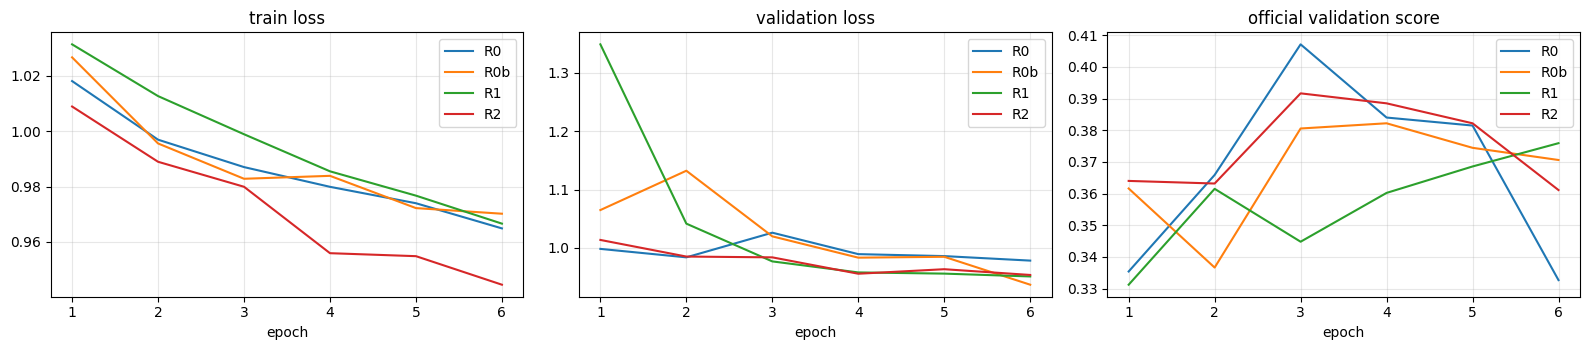

In [38]:
run_experiment("R0",  seed=42, warmup_cosine=False, sampler=False)
run_experiment("R0b", seed=7,  warmup_cosine=False, sampler=False)
run_experiment("R1_warmup_cosine", seed=42, warmup_cosine=True,  sampler=False)      # = the Question 8 run
run_experiment("R2_sqrt_sampler",  seed=42, warmup_cosine=False, sampler=True)
RUNS["R1"], RUNS["R2"] = RUNS.pop("R1_warmup_cosine"), RUNS.pop("R2_sqrt_sampler")
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for k, r in RUNS.items():
    ax[0].plot(r["hist"].epoch, r["hist"].train_loss, label=k); ax[1].plot(r["hist"].epoch, r["hist"].val_loss, label=k); ax[2].plot(r["hist"].epoch, r["hist"].val_score, label=k)
for a, t in zip(ax, ["train loss", "validation loss", "official validation score"]): a.set_title(t); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Question 8 — training dynamics and checkpoint selection (run R1)

In [39]:
h = RUNS["R1"]["hist"].set_index("epoch"); display(h.round(4))
q8_a = int(h.val_loss.idxmin())
q8_b_ep, q8_b_sc = int(h.val_score.idxmax()), float(h.val_score.max())
last = h.iloc[-1]; q8_c = float(last.val_loss - last.train_loss)
still_falling = h.val_loss.idxmin() == h.index[-1]
rising_after_min = (h.val_loss.iloc[-1] > h.val_loss.min() + 0.01) and (h.train_loss.iloc[-1] < h.train_loss.iloc[int(h.val_loss.values.argmin())])
pattern = "overfitting" if rising_after_min else ("still underfitting (train and val loss still falling)" if still_falling else "healthy convergence")
q8_d = f"Monitor the official validation score (with val loss as a cross-check); keep the epoch-{q8_b_ep} checkpoint; curves show {pattern}."
print(f"(a) lowest validation loss at epoch {q8_a}\n(b) best official validation score at epoch {q8_b_ep}: {q8_b_sc:.3f}\n(c) generalization gap at epoch {int(h.index[-1])}: {q8_c:.3f}\n(d) {q8_d}")
ANS["Q8"] = f"{q8_a}; {q8_b_ep}, {q8_b_sc:.3f}; {q8_c:.3f}; {q8_d}"

,train_loss,lr,val_loss,val_score,val_fg_dice,val_empty_acc,false_alarm_pct
epoch,,,,,,,
1,1.0315,0.0003,1.3491,0.3313,0.1117,0.6064,39.3564
2,1.0127,0.0003,1.0415,0.3615,0.1207,0.7958,20.4208
3,0.9989,0.0002,0.9767,0.3448,0.0753,0.9245,7.5495
4,0.9855,0.0001,0.9578,0.3602,0.1024,0.8911,10.8911
5,0.9767,0.0000,0.9557,0.3686,0.1155,0.8837,11.6337
6,0.9666,0.0000,0.9509,0.3759,0.1301,0.8564,14.3564


(a) lowest validation loss at epoch 6
(b) best official validation score at epoch 6: 0.376
(c) generalization gap at epoch 6: -0.016
(d) Monitor the official validation score (with val loss as a cross-check); keep the epoch-6 checkpoint; curves show still underfitting (train and val loss still falling).


## Question 10 — controlled experimentation (OFAT)

In [40]:
a = {k: RUNS[k]["best_score"] for k in ["R0", "R0b", "R1", "R2"]}
noise = abs(a["R0"] - a["R0b"]); gain1, gain2 = a["R1"] - a["R0"], a["R2"] - a["R0"]
c1, c2 = ("yes" if gain1 > 2 * noise else "no"), ("yes" if gain2 > 2 * noise else "no")
d0, d2 = RUNS["R0"]["fa_best"], RUNS["R2"]["fa_best"]
q10_e = "Because the gains of all three components would be mixed together, so a single combined run cannot be decomposed - you could not tell which component helped, which did nothing and which even hurt (OFAT changes one factor at a time)."
q10_f = ("The sampler raised the false-alarm rate: oversampling defect images shifts the training prior toward 'defect', so the model predicts defects more readily and fires on more clean images (prior shift), which then needs threshold / minimum-area calibration."
         if d2 > d0 else
         "The sampler did not raise the false-alarm rate here (it is equal or lower), so on this run the prior shift from oversampling defect images did not make the model fire more on clean images.")
print(f"(a) best val score: R0 {a['R0']:.3f} | R0b {a['R0b']:.3f} | R1 {a['R1']:.3f} | R2 {a['R2']:.3f}")
print(f"(b) noise band {noise:.3f} | gain R1 {gain1:+.3f} | gain R2 {gain2:+.3f}   (2x noise = {2 * noise:.3f})")
print(f"(c) R1 exceeds 2x noise: {c1} | R2 exceeds 2x noise: {c2}\n(d) clean-image false-alarm rate (best checkpoint, thr 0.5): R0 {d0:.1f} % | R2 {d2:.1f} %\n(e) {q10_e}\n(f) {q10_f}")
ANS["Q10"] = f"{a['R0']:.3f}, {a['R0b']:.3f}, {a['R1']:.3f}, {a['R2']:.3f}; {noise:.3f}, {gain1:.3f}, {gain2:.3f}; {c1}, {c2}; {d0:.1f}, {d2:.1f}; {q10_e}; {q10_f}"

(a) best val score: R0 0.407 | R0b 0.382 | R1 0.376 | R2 0.392
(b) noise band 0.025 | gain R1 -0.031 | gain R2 -0.015   (2x noise = 0.050)
(c) R1 exceeds 2x noise: no | R2 exceeds 2x noise: no
(d) clean-image false-alarm rate (best checkpoint, thr 0.5): R0 24.4 % | R2 23.9 %
(e) Because the gains of all three components would be mixed together, so a single combined run cannot be decomposed - you could not tell which component helped, which did nothing and which even hurt (OFAT changes one factor at a time).
(f) The sampler did not raise the false-alarm rate here (it is equal or lower), so on this run the prior shift from oversampling defect images did not make the model fire more on clean images.
